# ILMTv2_RSO — Reproducible Streak Detection Research Notebook
**Version:** research prototype, not a validated contest submission  
**Goal:** build a transparent baseline, audit the FITS data, test a physically motivated line detector, and evaluate it using synthetic injection/recovery before making performance claims.

## Research rules
1. Keep the organizers' reference notebook unchanged; this notebook is a separate experiment.
2. Never call a candidate a true detection merely because the contest guarantees at least one streak in each frame.
3. Separate **candidate generation**, **candidate validation**, and **parameter measurement**.
4. Do not call a score “probability”, “sigma significance”, or calibrated photometric SNR unless it has been calibrated.
5. Do not train a segmentation network without labels. Synthetic injection is useful, but does not replace real-data validation.
6. Save intermediate diagnostics and record all thresholds/configuration in the output.

### Literature motivating the first experiment
- Nir, Zackay & Ofek (2018), *Optimal and Efficient Streak Detection in Astronomical Images*: PSF-broadened line templates and Radon-based search. https://arxiv.org/abs/1806.04204
- Hickson (2018), *A fast algorithm for the detection of faint orbital debris tracks in optical images*: matched filtering + fast discrete Radon transform. https://arxiv.org/abs/1809.00239
- Stoppa et al. (2024), ASTA: U-Net followed by probabilistic Hough, trained on manually labelled data. https://www.aanda.org/articles/aa/abs/2024/12/aa51663-24/aa51663-24.html

These papers motivate candidate methods, not guaranteed performance on ILMT. Instrument/domain differences must be measured.

**v2.2 single-fix scope:** Corrected only the Radon overlay display-coordinate mapping. The prior v2.1 overlay incorrectly flipped y despite using `imshow(origin="lower")`, reversing the displayed line slope. All detector logic and preprocessing remain unchanged. A synthetic Radon geometry self-test is included so this coordinate convention can be verified before interpreting a real-frame overlay.


## 0. Experimental question and staged plan

We will not add every proposed module at once. That would make it impossible to know which change helped.

**Ablation ladder**
- **A0 — data audit:** verify FITS dimensions, dtype, invalid pixels, headers and display scaling.
- **A1 — reference-style baseline:** LoG edges + Hough line detection, used as a baseline rather than assumed ground truth.
- **A2 — intensity-domain Radon:** background-subtracted intensity rather than binary edges.
- **A3 — noise-aware scoring:** local noise/variance normalization and a validity mask.
- **A4 — PSF-aware matched filtering:** only after we have a defensible PSF estimate.
- **A5 — finite-length refinement:** estimate endpoints from the longitudinal profile, not from the infinite Radon line.
- **A6 — candidate validation:** compare against star fields, borders, cosmic-ray-like structures and local parallel strips.
- **A7 — injection/recovery:** measure completeness and false alarms as a function of injected streak properties.
- **A8 — only if justified:** a small candidate classifier, trained with synthetic and carefully reviewed real candidates.

**Important:** this notebook initially implements a transparent prototype for A0–A3 and a controlled injection benchmark. It intentionally does not claim that A4–A8 are solved. Run the cells and inspect results before proceeding.

In [1]:
# Cell 1 — Environment and imports
from pathlib import Path
import os, sys, json, math, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch
from scipy import ndimage as ndi
from scipy.signal import find_peaks
from skimage.feature import canny
from skimage.transform import hough_line, hough_line_peaks, radon, resize
from skimage.filters import gaussian, threshold_otsu
from skimage.draw import line as raster_line

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.set_printoptions(precision=4, suppress=True)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

Python: 3.13.13
Platform: Linux-7.0.0-38-generic-x86_64-with-glibc2.43


In [2]:
# Cell 2 — Set paths
# Edit DATA_DIR to the folder containing the contest's test_files directory.
DATA_DIR = Path("./ILMT_Contest_Materials/test_files")
OUTPUT_DIR = Path("./ILMTv2_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fits_files = sorted(DATA_DIR.glob("*.fits"))
print("Data directory exists:", DATA_DIR.exists())
print("FITS frames found:", len(fits_files))
print("First few:", [p.name for p in fits_files[:8]])

if not fits_files:
    print("No FITS files found. Set DATA_DIR to your local test_files folder before continuing.")

Data directory exists: True
FITS frames found: 85
First few: ['20221025-0028.fits', '20221026-0057.fits', '20221026-0059.fits', '20221031-0020.fits', '20221101-0030.fits', '20230317-0008.fits', '20230418-0005.fits', '20230513-0034.fits']


## 1. Data quality audit

FITS is a scientific data container, not a guarantee that a file is raw or calibrated. We must inspect the actual headers and pixel arrays. Missing gain/read-noise keywords mean we cannot honestly compute instrument-calibrated electron SNR from guessed defaults.

The audit below checks every primary image HDU and records:
- shape, dtype, finite-pixel fraction and robust location/scale;
- standard observing/instrument keywords if present;
- WCS keyword presence (not proof that WCS is valid);
- possible border anomalies for later inspection.

We do **not** modify files in place.

In [3]:
# Cell 3 — FITS header/data audit
def robust_stats(arr):
    finite = np.asarray(arr)[np.isfinite(arr)]
    if finite.size == 0:
        return {"median": np.nan, "robust_sigma": np.nan, "min": np.nan, "max": np.nan}
    _, med, std = sigma_clipped_stats(finite, sigma=3.0, maxiters=5)
    return {
        "median": float(med),
        "robust_sigma": float(std),
        "min": float(np.min(finite)),
        "max": float(np.max(finite)),
    }

HEADER_KEYS = [
    "DATE-OBS", "EXPTIME", "TELESCOP", "INSTRUME", "FILTER",
    "GAIN", "DETGAIN", "RDNOISE", "READNOISE", "SATURATE",
    "BITPIX", "NAXIS", "NAXIS1", "NAXIS2",
    "CTYPE1", "CTYPE2", "CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2"
]

def audit_one_fits(path):
    with fits.open(path, memmap=True) as hdul:
        # Primary HDU first; inspect extensions if primary has no image.
        hdu = next((h for h in hdul if getattr(h, "data", None) is not None and np.ndim(h.data) >= 2), hdul[0])
        header = hdu.header.copy()
        data = np.asarray(hdu.data)
        row = {"filename": path.name, "hdu": hdul.index_of(hdu),
               "shape": str(data.shape), "dtype": str(data.dtype),
               "finite_fraction": float(np.isfinite(data).mean()) if data.size else np.nan}
        row.update(robust_stats(data))
        for key in HEADER_KEYS:
            row[key] = header.get(key, None)
        row["has_wcs_keywords"] = any(k in header for k in ["CTYPE1", "CRVAL1", "CD1_1", "CDELT1"])
        return row

audit_rows = []
for p in fits_files:
    try:
        audit_rows.append(audit_one_fits(p))
    except Exception as e:
        audit_rows.append({"filename": p.name, "audit_error": repr(e)})

audit_df = pd.DataFrame(audit_rows)
display(audit_df.head(10))
audit_df.to_csv(OUTPUT_DIR / "fits_audit.csv", index=False)
print("Saved:", OUTPUT_DIR / "fits_audit.csv")

,filename,hdu,shape,dtype,finite_fraction,median,robust_sigma,min,max,DATE-OBS,...,NAXIS,NAXIS1,NAXIS2,CTYPE1,CTYPE2,CRVAL1,CRVAL2,CRPIX1,CRPIX2,has_wcs_keywords
0,20221025-0028.fits,0,"(4096, 4096)",>f4,1.0,-2.218965,18.259584,-1482.403076,65960.015625,2022-10-25,...,2,4096,4096,RA---CAR-SIP,DEC--CAR-SIP,19.119588,29.351569,2048.500000,-2047.5,True
1,20221026-0057.fits,0,"(4096, 4096)",>f4,1.0,-4.359012,37.039211,-1525.989502,64366.152344,2022-10-26,...,2,4096,4096,RA---CAR-SIP,DEC--CAR-SIP,92.675392,29.353233,2048.500000,-14335.5,True
2,20221026-0059.fits,0,"(4096, 4096)",>f4,1.0,-1.059986,19.764795,-1522.075562,57495.144531,2022-10-26,...,2,4096,4096,RA---CAR-SIP,DEC--CAR-SIP,101.621725,29.353305,2048.500000,18432.5,True
3,20221031-0020.fits,0,"(4096, 4096)",>f4,1.0,-1.040618,15.595767,-1236.222534,49490.660156,2022-10-31,...,2,4096,4096,RA---CAR-SIP,DEC--CAR-SIP,358.081332,29.351296,2048.500000,-2047.5,True
4,20221101-0030.fits,0,"(4096, 4096)",>f4,1.0,1.781234,21.654753,-1712.426025,52545.703125,2022-11-01,...,2,4096,4096,RA---CAR-SIP,DEC--CAR-SIP,37.374540,29.351950,2048.500000,18432.5,True
5,20230317-0008.fits,0,"(4096, 4096)",>f4,1.0,454.106171,29.808758,400.310608,79536.882812,2023-03-17,...,2,4096,4096,RA---CAR,DEC--CAR,119.874476,0.000000,325431.649516,18432.5,True
6,20230418-0005.fits,0,"(4096, 4096)",>f4,1.0,1577.998291,21.809507,1493.974487,66335.445312,2023-04-18,...,2,4096,4096,RA---CAR,DEC--CAR,155.381131,0.000000,325410.271555,18432.5,True
7,20230513-0034.fits,0,"(4096, 4096)",>f4,1.0,3154.432373,140.368042,-717.654053,107137.546875,2023-05-13,...,2,4096,4096,RA---CAR,DEC--CAR,289.632701,0.000000,325476.965023,-14335.5,True
8,20230514-0032.fits,0,"(4096, 4096)",>f4,1.0,2170.323486,83.436035,2018.515015,107561.898438,2023-05-14,...,2,4096,4096,RA---CAR,DEC--CAR,285.127002,0.000000,325506.914052,-10239.5,True
9,20230519-0009.fits,0,"(4096, 4096)",>f4,1.0,1418.135620,26.814808,1341.668213,77010.898438,2023-05-19,...,2,4096,4096,RA---CAR,DEC--CAR,249.121558,0.000000,325520.346681,18432.5,True


Saved: ILMTv2_outputs/fits_audit.csv


In [7]:
# Cell 4 — Inspect missing calibration metadata and image dimensions
if len(audit_df):
    display(audit_df[["filename", "shape", "dtype", "finite_fraction",
                      "median", "robust_sigma", "GAIN", "RDNOISE", "EXPTIME",
                      "has_wcs_keywords"]].head(20))
    for key in ["GAIN", "RDNOISE", "EXPTIME", "CTYPE1", "CRVAL1"]:
        if key in audit_df:
            print(f"{key}: present in {(audit_df[key].notna()).sum()}/{len(audit_df)} frames")

print("\nInterpretation:")
print("- Missing GAIN/RDNOISE means do not invent calibrated electron SNR.")
print("- WCS keyword presence needs astropy.wcs validation before using sky coordinates.")
print("- Different shapes/dtypes or non-finite pixels need explicit handling.")

,filename,shape,dtype,finite_fraction,median,robust_sigma,GAIN,RDNOISE,EXPTIME,has_wcs_keywords
0,20221025-0028.fits,"(4096, 4096)",>f4,1.0,-2.218965,18.259584,None,None,102.345506,True
1,20221026-0057.fits,"(4096, 4096)",>f4,1.0,-4.359012,37.039211,None,None,102.345506,True
2,20221026-0059.fits,"(4096, 4096)",>f4,1.0,-1.059986,19.764795,None,None,102.345506,True
3,20221031-0020.fits,"(4096, 4096)",>f4,1.0,-1.040618,15.595767,None,None,102.345506,True
4,20221101-0030.fits,"(4096, 4096)",>f4,1.0,1.781234,21.654753,None,None,102.345506,True
5,20230317-0008.fits,"(4096, 4096)",>f4,1.0,454.106171,29.808758,None,None,102.345506,True
6,20230418-0005.fits,"(4096, 4096)",>f4,1.0,1577.998291,21.809507,None,None,102.345506,True
7,20230513-0034.fits,"(4096, 4096)",>f4,1.0,3154.432373,140.368042,None,None,102.345506,True
8,20230514-0032.fits,"(4096, 4096)",>f4,1.0,2170.323486,83.436035,None,None,102.345506,True
9,20230519-0009.fits,"(4096, 4096)",>f4,1.0,1418.135620,26.814808,None,None,102.345506,True


GAIN: present in 0/85 frames
RDNOISE: present in 0/85 frames
EXPTIME: present in 84/85 frames
CTYPE1: present in 85/85 frames
CRVAL1: present in 85/85 frames

Interpretation:
- Missing GAIN/RDNOISE means do not invent calibrated electron SNR.
- WCS keyword presence needs astropy.wcs validation before using sky coordinates.
- Different shapes/dtypes or non-finite pixels need explicit handling.


In [19]:
# Cell 5 — Load one frame safely
def load_fits_image(path):
    with fits.open(path, memmap=False) as hdul:
        hdu = next((h for h in hdul if getattr(h, "data", None) is not None and np.ndim(h.data) == 2), None)
        if hdu is None:
            raise ValueError(f"No 2-D image HDU found in {path}")
        image = np.asarray(hdu.data, dtype=np.float64)
        header = hdu.header.copy()
    valid = np.isfinite(image)
    if valid.sum() == 0:
        raise ValueError(f"No finite pixels in {path}")
    return image, valid, header

if fits_files:
    sample_path = fits_files[1]
    image, valid, header = load_fits_image(sample_path)
    print(sample_path.name, image.shape, image.dtype, "finite:", valid.mean())
    print("Header keys:", list(header.keys())[:30])

20221026-0057.fits (4096, 4096) float64 finite: 1.0
Header keys: ['SIMPLE', 'BITPIX', 'NAXIS', 'NAXIS1', 'NAXIS2', 'DATE-OBS', 'DATE', 'UTSTART', 'N_PARAM', 'PARAM0', 'PARAM1', 'PARAM2', 'PARAM3', 'PARAM4', 'PARAM5', 'PARAM6', 'PARAM7', 'PARAM8', 'PARAM9', 'PARAM10', 'PARAM11', 'PARAM12', 'PARAM13', 'PARAM14', 'PARAM15', 'PARAM16', 'PARAM17', 'PARAM18', 'PARAM19', 'PARAM20']


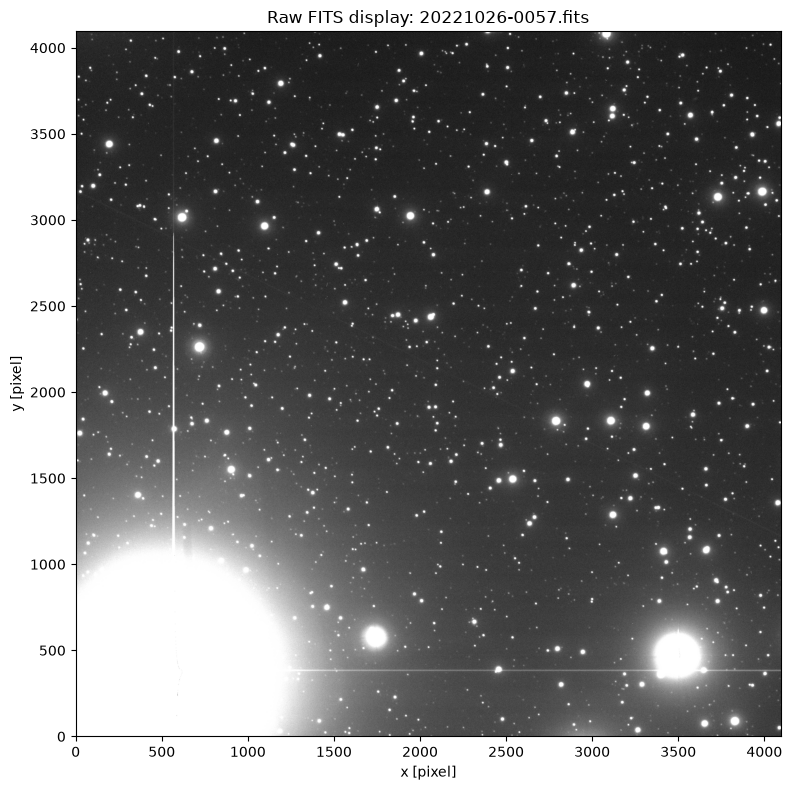

In [20]:
# Cell 6 — Visual inspection using robust display scaling
def show_image(image, title="", valid=None, figsize=(9, 8)):
    arr = np.asarray(image, dtype=float)
    finite = np.isfinite(arr) if valid is None else (np.isfinite(arr) & valid)
    vals = arr[finite]
    if vals.size == 0:
        raise ValueError("No finite pixels to display")
    lo, hi = ZScaleInterval().get_limits(vals)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(np.ma.array(arr, mask=~finite), origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")
    plt.tight_layout()
    plt.show()

if fits_files:
    show_image(image, f"Raw FITS display: {sample_path.name}", valid)

## 2. Background and noise: what these estimates mean

We subtract a slowly varying sky/background estimate, but keep the original image and a validity mask. We do **not** replace masked stars with random noise: random infill makes results stochastic and can alter the line score.

For a first transparent baseline, use a robust median filter as a smooth background approximation. This is not universally optimal: filter size must be large compared with the streak width and small enough to follow real background variation. Compare it visually against `sep.Background` or another astronomical background estimator if `sep` is installed.

The local noise estimate below is a robust rolling MAD. It is an empirical scale estimate, not a complete CCD noise model. Correlated pixels, resampling, source wings and detector artifacts can violate simple independent-noise assumptions.

Residual median: 0.17233694082182893
Median local robust noise scale: 18.319535445444075


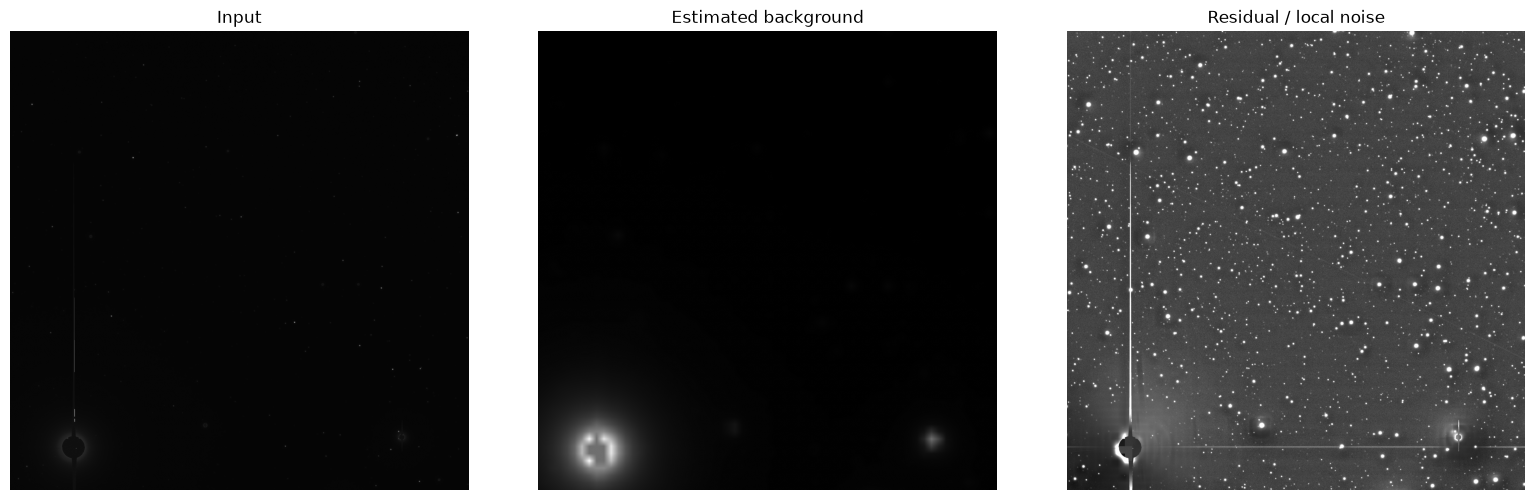

In [21]:
# Cell 7 — Robust background and local noise maps
def robust_mad_sigma(values, axis=None):
    values = np.asarray(values, dtype=float)
    med = np.nanmedian(values, axis=axis, keepdims=True)
    mad = np.nanmedian(np.abs(values - med), axis=axis)
    return 1.4826 * mad

def estimate_background_noise(image, valid=None, background_size=64, noise_size=64):
    image = np.asarray(image, dtype=float)
    valid = np.isfinite(image) if valid is None else (np.isfinite(image) & valid)
    safe = np.where(valid, image, np.nan)

    # Robust local medians on a coarse grid, interpolated to full resolution.
    h, w = image.shape
    ys = np.arange(0, h, background_size)
    xs = np.arange(0, w, background_size)
    grid = np.full((len(ys), len(xs)), np.nan)
    noise_grid = np.full_like(grid, np.nan)

    for iy, y0 in enumerate(ys):
        for ix, x0 in enumerate(xs):
            tile = safe[y0:min(y0+background_size,h), x0:min(x0+background_size,w)]
            vals = tile[np.isfinite(tile)]
            if vals.size >= 20:
                grid[iy, ix] = np.median(vals)
                noise_grid[iy, ix] = robust_mad_sigma(vals)

    # Fill empty grid cells using nearest valid grid cell; avoid NaNs leaking into interpolation.
    for g in (grid, noise_grid):
        good = np.isfinite(g)
        if not good.any():
            raise ValueError("Could not estimate background/noise from valid pixels")
        if not good.all():
            inds = ndi.distance_transform_edt(~good, return_distances=False, return_indices=True)
            g[~good] = g[tuple(inds[:, ~good])]

    bg = ndi.zoom(grid, (h/grid.shape[0], w/grid.shape[1]), order=1)
    sig = ndi.zoom(noise_grid, (h/noise_grid.shape[0], w/noise_grid.shape[1]), order=1)
    bg = bg[:h, :w]
    sig = sig[:h, :w]
    # Keep the noise scale positive and finite.
    global_sig = float(np.nanmedian(sig[valid]))
    sig = np.where(np.isfinite(sig) & (sig > 0), sig, global_sig)
    return bg, sig, valid

if fits_files:
    background, noise_map, valid = estimate_background_noise(image, valid)
    residual = image - background
    print("Residual median:", float(np.nanmedian(residual[valid])))
    print("Median local robust noise scale:", float(np.nanmedian(noise_map[valid])))
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(image, origin="lower", cmap="gray"); ax[0].set_title("Input")
    ax[1].imshow(background, origin="lower", cmap="gray"); ax[1].set_title("Estimated background")
    ax[2].imshow(residual / np.maximum(noise_map, 1e-6), origin="lower", cmap="gray", vmin=-3, vmax=8); ax[2].set_title("Residual / local noise")
    for a in ax: a.set_axis_off()
    plt.tight_layout()
    plt.show()

## 3. Baseline A1: reference-style LoG + Hough

This is a **transparent comparison baseline**, not a byte-for-byte reproduction of every cell in the organizers' notebook. The reference notebook should remain the authoritative implementation of their output schema and baseline details.

The baseline thresholds a LoG response, then uses Hough voting on edges. This can work for crisp, bright lines but can lose faint intensity information and generate many edge responses around stars. We will record the result and inspect it; we do not assume every returned line is an RSO.

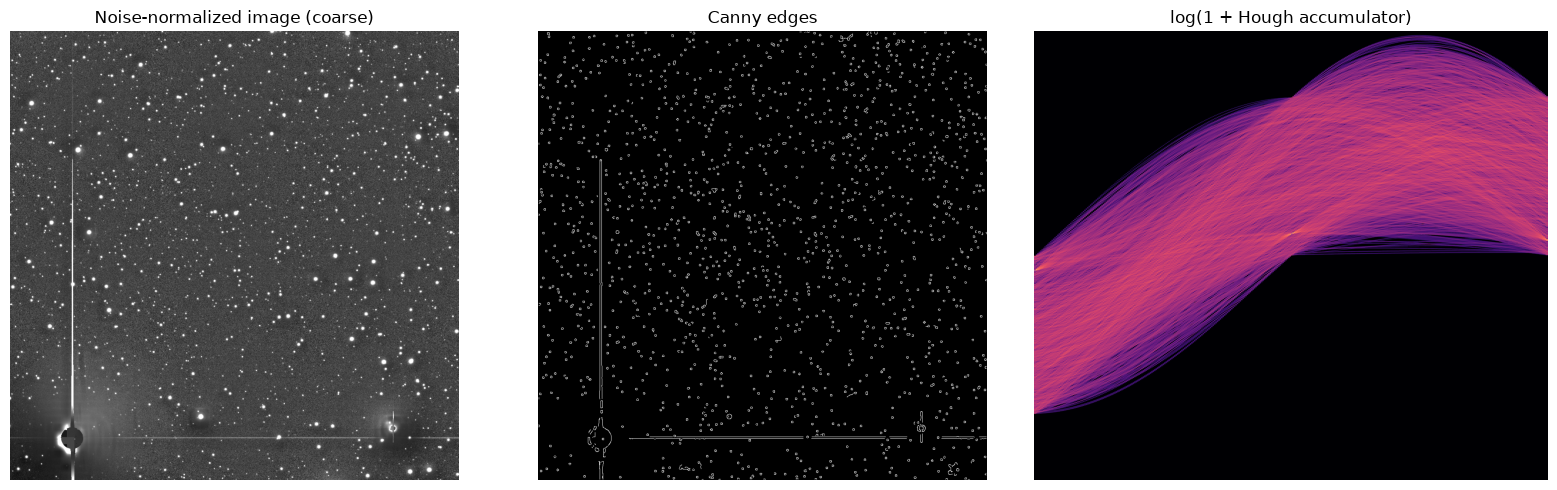

Top Hough candidates: [{'theta_rad': -1.5707963267948966, 'rho_small': -94.0, 'votes': 675, 'scale': 0.25}, {'theta_rad': 0.0, 'rho_small': 140.0, 'votes': 563, 'scale': 0.25}]


In [22]:
# Cell 8 — LoG + Hough baseline
def log_hough_baseline(image, valid=None, downsample_max=1024, angles=360):
    image = np.asarray(image, dtype=float)
    valid = np.isfinite(image) if valid is None else (np.isfinite(image) & valid)
    bg, noise, valid = estimate_background_noise(image, valid, background_size=64)
    z = (image - bg) / np.maximum(noise, 1e-6)
    z[~valid] = 0.0

    scale = min(1.0, downsample_max / max(z.shape))
    if scale < 1:
        z_small = ndi.zoom(z, scale, order=1)
    else:
        z_small = z.copy()

    # Edge detection is deliberately explicit and fixed for baseline comparability.
    smoothed = ndi.gaussian_filter(z_small, sigma=1.0)
    edges = canny(smoothed, sigma=1.5, low_threshold=0.5, high_threshold=2.0)
    hspace, theta, dist = hough_line(edges, theta=np.linspace(-np.pi/2, np.pi/2, angles, endpoint=False))
    acc, ang, rho = hough_line_peaks(hspace, theta, dist, num_peaks=10,
                                      threshold=max(1, 0.25 * np.max(hspace)))
    candidates = []
    for a, r, votes in zip(ang, rho, acc):
        candidates.append({"theta_rad": float(a), "rho_small": float(r),
                           "votes": int(votes), "scale": float(scale)})
    return {"z_small": z_small, "edges": edges, "hspace": hspace,
            "theta": theta, "dist": dist, "candidates": candidates}

if fits_files:
    baseline = log_hough_baseline(image, valid)
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(baseline["z_small"], origin="lower", cmap="gray", vmin=-3, vmax=8)
    ax[0].set_title("Noise-normalized image (coarse)")
    ax[1].imshow(baseline["edges"], origin="lower", cmap="gray")
    ax[1].set_title("Canny edges")
    ax[2].imshow(np.log1p(baseline["hspace"]), origin="lower", aspect="auto", cmap="magma")
    ax[2].set_title("log(1 + Hough accumulator)")
    for a in ax: a.set_axis_off()
    plt.tight_layout()
    plt.show()
    print("Top Hough candidates:", baseline["candidates"][:5])

## 4. Radon is a search primitive, not a verdict

A Radon projection sums image values along lines indexed by angle and offset. A real line-like signal can add coherently, while independent zero-mean noise tends to partially cancel. However:
- an unweighted sum favours longer paths;
- star alignments, borders, bleed columns and other artifacts can also make peaks;
- Radon accumulator samples are correlated;
- selecting the maximum over many angles/offsets introduces a look-elsewhere effect.

Therefore the raw maximum divided by the accumulator MAD is only a **ranking statistic**, not a calibrated Gaussian significance. The next cell uses a noise-normalized image and returns candidate parameters for inspection; it does not claim a false-positive-controlled detection.

In [27]:
def _same_radon_line(a, b, angle_tol_deg=2.0, rho_tol_px=8.0):
    """
    Determine whether two Radon candidates represent approximately
    the same infinite line.

    rho_tol_px is measured in coarse-image pixels.
    """
    theta_a = float(a["theta_deg"])
    theta_b = float(b["theta_deg"])

    rho_a = float(a["rho_centered_coarse"])
    rho_b = float(b["rho_centered_coarse"])

    raw_angle_difference = abs(theta_a - theta_b)

    # Radon line orientation is periodic over 180 degrees.
    angle_difference = min(
        raw_angle_difference,
        180.0 - raw_angle_difference
    )

    if angle_difference >= angle_tol_deg:
        return False, angle_difference, np.inf

    # Crossing the 0/180-degree boundary reverses rho's sign.
    if raw_angle_difference > 90.0:
        rho_b = -rho_b

    rho_difference = abs(rho_a - rho_b)

    same_line = rho_difference < rho_tol_px

    return same_line, angle_difference, rho_difference

,theta_deg,rho_index,radon_sum_z,scale,coarse_shape,rho_centered_coarse
0,0.0,354,48380.614017,0.25,"(1024, 1024)",-370.0
1,179.5,1094,31234.027755,0.25,"(1024, 1024)",370.0
2,2.0,359,13617.890830,0.25,"(1024, 1024)",-365.0
3,4.0,357,9313.992916,0.25,"(1024, 1024)",-367.0
4,5.0,365,8892.271218,0.25,"(1024, 1024)",-359.0
5,177.5,1099,8564.021015,0.25,"(1024, 1024)",375.0
6,6.5,378,7985.099674,0.25,"(1024, 1024)",-346.0
7,2.5,346,7561.458773,0.25,"(1024, 1024)",-378.0
8,175.0,1156,6992.739804,0.25,"(1024, 1024)",432.0
9,8.0,390,6542.700554,0.25,"(1024, 1024)",-334.0


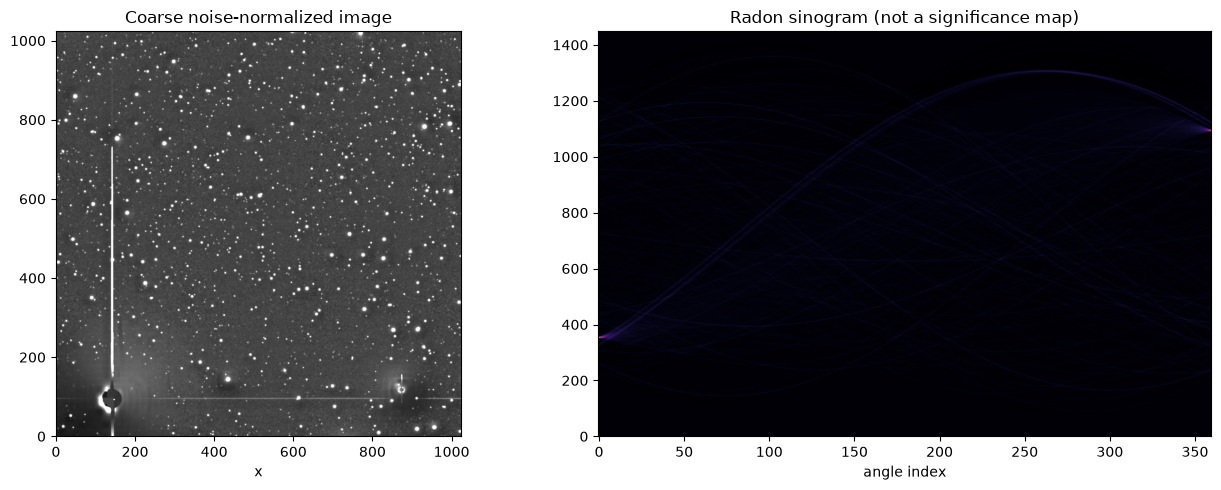

In [ ]:
# Cell 9 — Intensity-domain Radon candidate search
def radon_candidates(image, valid=None, background_size=64, max_side=1024,
                     n_angles=360, top_k=12, min_separation=12):
    image = np.asarray(image, dtype=float)
    valid = np.isfinite(image) if valid is None else (np.isfinite(image) & valid)
    bg, noise, valid = estimate_background_noise(image, valid, background_size=background_size)
    residual = image - bg
    z = residual / np.maximum(noise, 1e-6)
    z[~valid] = 0.0

    scale = min(1.0, max_side / max(z.shape))
    if scale < 1:
        zc = ndi.zoom(z, scale, order=1)
        vc = ndi.zoom(valid.astype(float), scale, order=0) > 0.5
    else:
        zc, vc = z.copy(), valid.copy()

    # Light PSF-scale smoothing is a hyperparameter to test, not an established truth.
    zc = ndi.gaussian_filter(zc, sigma=0.8)
    zc[~vc] = 0.0
    theta_deg = np.linspace(0.0, 180.0, n_angles, endpoint=False)
    sino = radon(zc, theta=theta_deg, circle=False, preserve_range=True)

    # Candidate peaks are selected per angle in rho, then globally ranked.
    records = []
    for j, angle in enumerate(theta_deg):
        col = sino[:, j]
        peaks, props = find_peaks(col, distance=min_separation)
        if peaks.size == 0:
            continue
        order = np.argsort(col[peaks])[::-1][:max(2, top_k // 3)]
        for oi in order:
            ri = int(peaks[oi])
            records.append({
                "theta_deg": float(angle),
                "rho_index": ri,
                "radon_sum_z": float(col[ri]),
                "scale": float(scale),
                "coarse_shape": tuple(zc.shape),
                "rho_centered_coarse": float(ri - (sino.shape[0]//2))
            })

    records.sort(key=lambda r: r["radon_sum_z"], reverse=True)

    # Deduplicate equivalent Radon lines.
    selected = []
    duplicate_log = []

    for r in records:
        matched_candidate = None
        matched_metrics = None

        for q in selected:
            is_same, angle_diff, rho_diff = _same_radon_line(
                r,
                q,
                angle_tol_deg=2.0,
                rho_tol_px=8.0
            )

            if is_same:
                matched_candidate = q
                matched_metrics = (angle_diff, rho_diff)
                break

        if matched_candidate is not None:
            angle_diff, rho_diff = matched_metrics

            duplicate_log.append({
                "discarded_theta_deg": r["theta_deg"],
                "discarded_rho": r["rho_centered_coarse"],
                "discarded_score": r["radon_sum_z"],
                "kept_theta_deg": matched_candidate["theta_deg"],
                "kept_rho": matched_candidate["rho_centered_coarse"],
                "kept_score": matched_candidate["radon_sum_z"],
                "angle_difference_deg": angle_diff,
                "rho_difference_coarse_px": rho_diff,
            })

            continue

        selected.append(r)

        if len(selected) >= top_k:
            break
        
    return {"candidates": selected, "sinogram": sino, "theta_deg": theta_deg,
            "z_coarse": zc, "residual": residual, "noise_map": noise, "valid": valid}

if fits_files:
    rad = radon_candidates(image, valid)
    display(pd.DataFrame(rad["candidates"]))
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(rad["z_coarse"], origin="lower", cmap="gray", vmin=-3, vmax=8)
    ax[0].set_title("Coarse noise-normalized image")
    ax[1].imshow(rad["sinogram"], origin="lower", aspect="auto", cmap="magma")
    ax[1].set_title("Radon sinogram (not a significance map)")
    for a in ax: a.set_xlabel("angle index" if a is ax[1] else "x")
    plt.tight_layout()
    plt.show()

## 5. Why this is not yet a matched-filter implementation

The published optimal formulation correlates the image with a **finite line template broadened by the measured PSF**, and accounts for noise. Gaussian smoothing followed by a generic Radon transform is only an approximation to that procedure.

Before calling the next version “matched filtering”, we need:
1. a defensible PSF estimate from isolated, unsaturated stars;
2. a finite-length template family;
3. a noise/validity-weighted score;
4. calibration of thresholds using null/background tests and injection/recovery.

We first need to verify that the image dimensions, orientation convention and candidate geometry are correct. The function below converts a Radon candidate to an approximate line for visualization only. Do not use this approximate line as final endpoints.

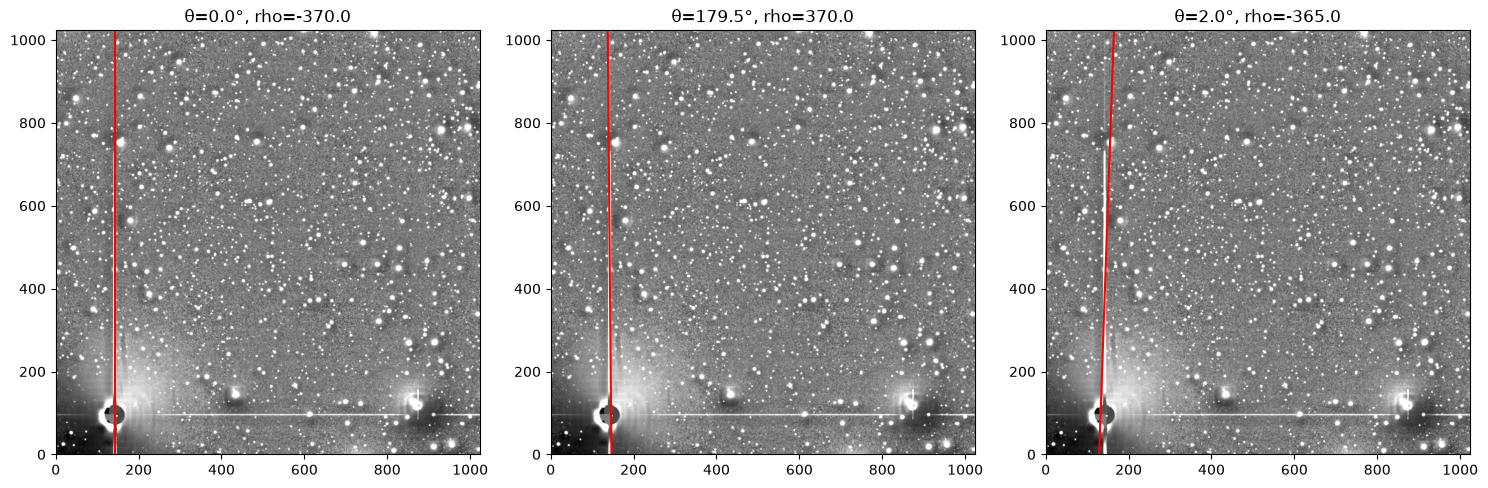

In [ ]:
# Cell 10 — Radon candidate overlays with explicit coordinate conventions
# IMPORTANT: skimage.transform.radon(..., circle=False) pads the image. Its
# sinogram row index is measured relative to the padded image centre. Because
# padding is centre-preserving, rho_centered_coarse is in the coarse input's
# centred pixel coordinates. With imshow(origin="lower"), array row index is
# already the plotted y coordinate. Do NOT apply an additional y -> h-1-y flip.
def overlay_radon_candidate(image, candidate, ax=None, title_prefix=""):
    arr = np.asarray(image, dtype=float)
    if arr.ndim != 2:
        raise ValueError("image must be 2-D")
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 6))
    finite = arr[np.isfinite(arr)]
    if finite.size == 0:
        raise ValueError("image contains no finite pixels")
    lo, hi = ZScaleInterval().get_limits(finite)
    h, w = arr.shape
    ax.imshow(arr, origin="lower", cmap="gray", vmin=lo, vmax=hi)

    theta = np.deg2rad(float(candidate["theta_deg"]))
    rho = float(candidate["rho_centered_coarse"])
    # skimage convention in array coordinates: (x-cx)*cos(theta) -
    # (y_row-cy)*sin(theta) = rho. Because this axis uses origin="lower",
    # plotting y_row directly preserves the correct slope.
    cx, cy = float(w // 2), float(h // 2)
    xs = np.linspace(0, w - 1, 500)
    if abs(np.sin(theta)) >= abs(np.cos(theta)):
        y_row = cy + ((xs - cx) * np.cos(theta) - rho) / np.sin(theta)
        good = (y_row >= 0) & (y_row <= h - 1)
        ax.plot(xs[good], y_row[good], "r-", lw=1.5)
    else:
        # Solve for x to avoid division by a small sin(theta).
        ys_row = np.linspace(0, h - 1, 500)
        x = cx + (rho + (ys_row - cy) * np.sin(theta)) / np.cos(theta)
        good = (x >= 0) & (x <= w - 1)
        ax.plot(x[good], ys_row[good], "r-", lw=1.5)

    ax.set_xlim(0, w - 1)
    ax.set_ylim(0, h - 1)
    ax.set_title(f"{title_prefix}θ={candidate['theta_deg']:.1f}°, rho={rho:.1f}")
    return ax

if fits_files and rad["candidates"]:
    fig, axes = plt.subplots(1, min(3, len(rad["candidates"])), figsize=(15, 5))
    if not isinstance(axes, np.ndarray): axes = np.array([axes])
    for ax, cand in zip(axes, rad["candidates"][:3]):
        # Overlay in the same coarse coordinate system used by the Radon transform.
        overlay_radon_candidate(rad["z_coarse"], cand, ax=ax)
    plt.tight_layout()
    plt.show()


Known theta/rho: 65.5 deg / 12.0 px
Recovered rho at known theta: 12.0 px
Expected displayed endpoints with origin=lower: y(x=0)=126.1, y(x=511)=359.0


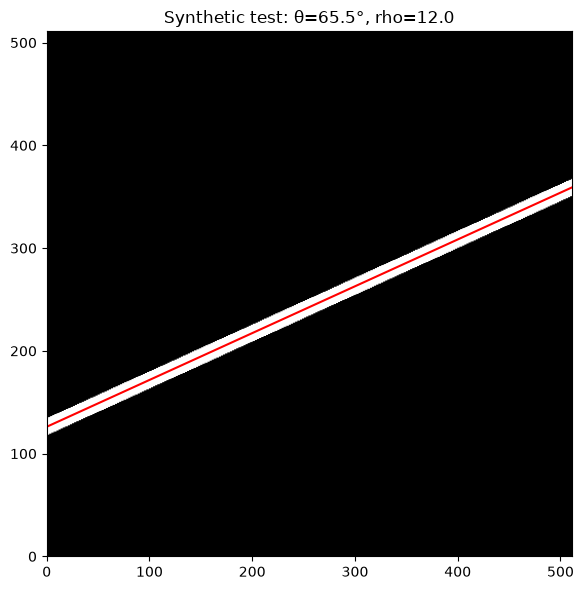

Geometry self-test passed. This validates coordinate mapping only, not detector sensitivity or accuracy on ILMT data.


In [25]:
# Cell 10A — Synthetic Radon geometry self-test (not a real-frame detection test)
# A known straight line must peak at the injected theta/rho, and its plotted slope
# should be positive for this convention when theta=65.5 degrees.
test_n = 512
test_cx = test_cy = test_n // 2
test_theta_deg = 65.5
test_rho = 12.0
test_theta = np.deg2rad(test_theta_deg)
test_yy, test_xx = np.indices((test_n, test_n), dtype=float)
test_dist = (test_xx-test_cx)*np.cos(test_theta) - (test_yy-test_cy)*np.sin(test_theta)
test_line = np.exp(-0.5*((test_dist-test_rho)/0.8)**2)
test_sino = radon(test_line, theta=np.array([test_theta_deg]), circle=False, preserve_range=True)
test_peak_row = int(np.argmax(test_sino[:, 0]))
test_rho_hat = float(test_peak_row - test_sino.shape[0]//2)
test_y_left = test_cy + ((0-test_cx)*np.cos(test_theta)-test_rho)/np.sin(test_theta)
test_y_right = test_cy + ((test_n-1-test_cx)*np.cos(test_theta)-test_rho)/np.sin(test_theta)
print(f"Known theta/rho: {test_theta_deg:.1f} deg / {test_rho:.1f} px")
print(f"Recovered rho at known theta: {test_rho_hat:.1f} px")
print(f"Expected displayed endpoints with origin=lower: y(x=0)={test_y_left:.1f}, y(x={test_n-1})={test_y_right:.1f}")
assert abs(test_rho_hat-test_rho) <= 1.5, "Synthetic Radon geometry self-test failed; inspect library/version convention before using overlays."
assert test_y_right > test_y_left, "Expected positive plotted slope for this synthetic line."
fig, ax = plt.subplots(figsize=(6, 6))
overlay_radon_candidate(test_line, {"theta_deg": test_theta_deg, "rho_centered_coarse": test_rho}, ax=ax, title_prefix="Synthetic test: ")
plt.tight_layout(); plt.show()
print("Geometry self-test passed. This validates coordinate mapping only, not detector sensitivity or accuracy on ILMT data.")

## 6. Finite-line scoring: the quantity we actually want

For a candidate finite segment, define a template \(T\) that is nonzero along a line segment and broadened across the track by the PSF. For a locally constant independent-noise model, a normalized matched-filter statistic has the form

\[
Z_T = \frac{\sum_{x,y} T(x,y)\,R(x,y)/\sigma(x,y)^2}
{\sqrt{\sum_{x,y} T(x,y)^2/\sigma(x,y)^2}},
\]

where \(R=I-B\) is the background-subtracted residual and \(\sigma(x,y)\) is a local noise scale. This expression motivates the score, but its Gaussian interpretation is only valid under the corresponding noise assumptions and before accounting for the search over many templates. The search maximum still needs empirical calibration.

The next cells create a **synthetic injection test** on a real background. This tests whether the code can recover known geometry and how its score changes with injected brightness. It does not by itself prove the injected morphology exactly matches real ILMT streaks.

Max |(injected - original) - synthetic signal|: 1.0658141036401503e-13


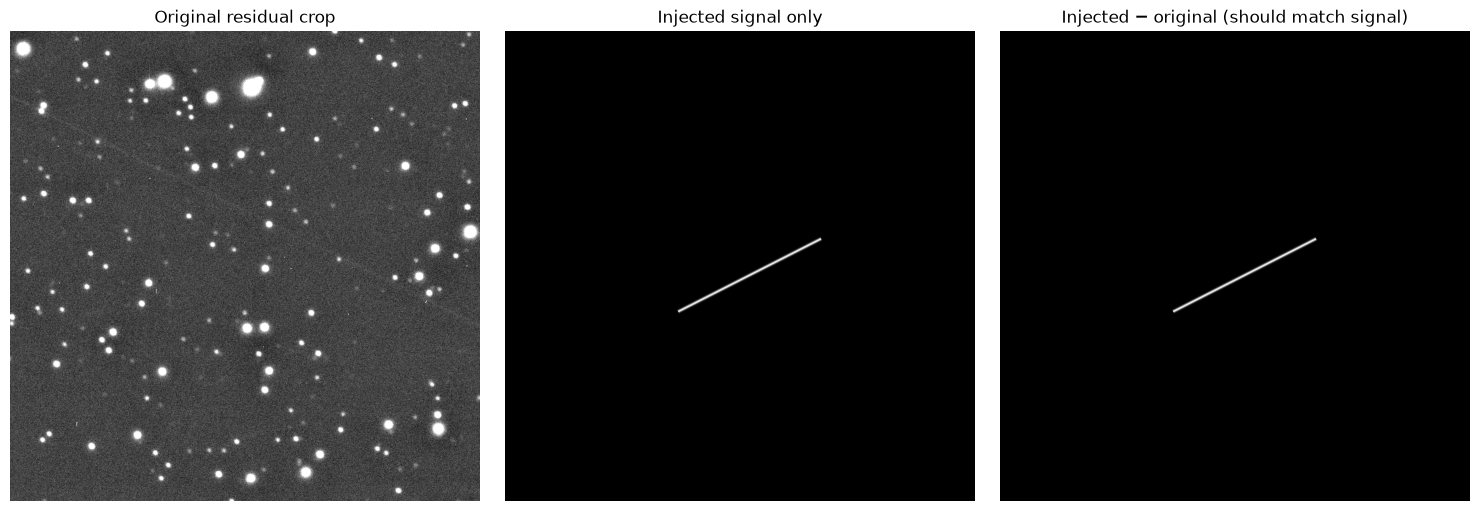

In [26]:
# Cell 11 — Inject a synthetic PSF-broadened finite streak into a residual image
# This is a controlled software test, not a claim that the injected line is a real RSO.
def inject_streak(residual, x0, y0, length, theta_deg, amplitude,
                  sigma_perp=2.0, profile="flat"):
    """Add a finite straight line with a Gaussian cross-track profile.
    x0/y0 are array pixel coordinates; theta_deg is measured from +x toward +y
    in array coordinates. amplitude is the peak added signal in image units.
    """
    base = np.asarray(residual, dtype=float)
    h, w = base.shape
    yy, xx = np.indices((h, w), dtype=float)
    th = np.deg2rad(theta_deg)
    dx, dy = np.cos(th), np.sin(th)
    along = (xx-x0)*dx + (yy-y0)*dy
    perp = -(xx-x0)*dy + (yy-y0)*dx
    inside = np.abs(along) <= length/2
    cross = np.exp(-0.5*(perp/max(sigma_perp, 1e-3))**2)
    taper = np.clip(1 - (np.abs(along)/(length/2+1e-9))**4, 0, 1) if profile == "tapered" else 1.0
    signal = amplitude * cross * taper * inside
    return base + signal, signal

if fits_files:
    crop_size = min(1024, image.shape[0], image.shape[1])
    cy, cx = image.shape[0]//2, image.shape[1]//2
    ys = slice(cy-crop_size//2, cy+crop_size//2)
    xs = slice(cx-crop_size//2, cx+crop_size//2)
    residual_crop = residual[ys, xs].copy()
    noise_crop = noise_map[ys, xs].copy()
    valid_crop = valid[ys, xs].copy()
    inj_img, inj_signal = inject_streak(
        residual_crop, x0=crop_size*0.52, y0=crop_size*0.48,
        length=min(350, crop_size*0.6), theta_deg=27,
        amplitude=3*np.nanmedian(noise_crop[valid_crop]), sigma_perp=2.0
    )
    # Difference must equal the known synthetic signal (up to floating-point error).
    injection_difference = inj_img - residual_crop
    print("Max |(injected - original) - synthetic signal|:",
          float(np.nanmax(np.abs(injection_difference - inj_signal))))
    lim = 8*np.nanmedian(noise_crop[valid_crop])
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(residual_crop, origin="lower", cmap="gray", vmin=-3*np.nanmedian(noise_crop[valid_crop]), vmax=lim)
    ax[0].set_title("Original residual crop")
    ax[1].imshow(inj_signal, origin="lower", cmap="gray")
    ax[1].set_title("Injected signal only")
    ax[2].imshow(injection_difference, origin="lower", cmap="gray", vmin=0, vmax=np.nanmax(inj_signal))
    ax[2].set_title("Injected − original (should match signal)")
    for a in ax: a.set_axis_off()
    plt.tight_layout()
    plt.show()


In [15]:
# Cell 12 — A simple finite-segment matched-filter score at a known geometry
def finite_line_template(shape, x0, y0, length, theta_deg, sigma_perp=2.0):
    h, w = shape
    yy, xx = np.indices((h, w), dtype=float)
    th = np.deg2rad(theta_deg)
    along = (xx-x0)*np.cos(th) + (yy-y0)*np.sin(th)
    perp = -(xx-x0)*np.sin(th) + (yy-y0)*np.cos(th)
    return (np.abs(along) <= length/2) * np.exp(-0.5*(perp/max(sigma_perp, 1e-3))**2)

def matched_filter_score(residual, noise, valid, template):
    residual = np.asarray(residual, float)
    noise = np.asarray(noise, float)
    valid = np.asarray(valid, bool) & np.isfinite(residual) & np.isfinite(noise) & (noise > 0)
    t = np.asarray(template, float)
    invvar = np.zeros_like(residual)
    invvar[valid] = 1.0 / noise[valid]**2
    denom2 = np.sum(t*t*invvar)
    if denom2 <= 0:
        return np.nan
    return float(np.sum(t*residual*invvar) / np.sqrt(denom2))

if fits_files:
    template = finite_line_template(
        residual_crop.shape, x0=crop_size*0.52, y0=crop_size*0.48,
        length=min(350, crop_size*0.6), theta_deg=27, sigma_perp=2.0
    )
    score_injected = matched_filter_score(inj_img, noise_crop, valid_crop, template)
    score_background = matched_filter_score(residual_crop, noise_crop, valid_crop, template)
    print("Matched-filter score on original residual (may already contain real streak signal):", score_background)
    print("Matched-filter score after injection:", score_injected)
    print("Difference (injection response):", score_injected-score_background)
    print("Caution: this is a known-location score; the original crop is not guaranteed to be background-only, and a blind-search maximum needs separate calibration.")

Matched-filter score on original residual (may already contain real streak signal): 9.937588824727426
Matched-filter score after injection: 48.545196361264345
Difference (injection response): 38.60760753653692
Caution: this is a known-location score; the original crop is not guaranteed to be background-only, and a blind-search maximum needs separate calibration.


## 7. Injection/recovery protocol (do this before tuning thresholds)

One injection is a demonstration, not a benchmark. The benchmark should sample:
- line length (short/medium/long);
- orientation;
- position (including near borders);
- amplitude / integrated signal-to-noise;
- width relative to measured PSF;
- intersections with stars and saturated sources;
- flat vs varying brightness;
- real backgrounds from many distinct frames.

For each injected signal, record whether a blind detector recovers a candidate close enough in angle, perpendicular offset and length. Also run the detector on **non-injected** real backgrounds to estimate false candidates. Do not choose the threshold on the same injections used for the final reported result.

In [16]:
# Cell 13 — Synthetic injection grid at known locations (known-position score only)
def injection_score_grid(residual, noise, valid, center=None,
                         lengths=(40, 100, 250), amplitudes_sigma=(0.5, 1, 2, 4),
                         angles=(0, 30, 60, 90, 135), sigma_perp=2.0):
    h, w = residual.shape
    if center is None:
        center = (w/2, h/2)
    x0, y0 = center
    rows = []
    local_noise = float(np.nanmedian(noise[valid]))
    for L in lengths:
        for a in amplitudes_sigma:
            for th in angles:
                t = finite_line_template(residual.shape, x0, y0, L, th, sigma_perp)
                inj, sig = inject_streak(residual, x0, y0, L, th,
                                         amplitude=a*local_noise, sigma_perp=sigma_perp)
                score0 = matched_filter_score(residual, noise, valid, t)
                score1 = matched_filter_score(inj, noise, valid, t)
                rows.append({
                    "length_px": L, "amplitude_in_local_sigma": a,
                    "theta_deg": th, "sigma_perp_px": sigma_perp,
                    "score_background": score0, "score_injected": score1,
                    "score_delta": score1-score0,
                    "injected_peak_signal": a*local_noise
                })
    return pd.DataFrame(rows)

if fits_files:
    injection_grid_df = injection_score_grid(residual_crop, noise_crop, valid_crop)
    display(injection_grid_df.head(12))
    injection_grid_df.to_csv(OUTPUT_DIR / "known_location_injection_scores.csv", index=False)
    print("Saved known-location score grid. This is not yet blind detection completeness.")

,length_px,amplitude_in_local_sigma,theta_deg,sigma_perp_px,score_background,score_injected,score_delta,injected_peak_signal
0,40,0.5,0,2.0,-7.367784,-4.267872,3.099911,8.565731
1,40,0.5,30,2.0,-7.949974,-4.903061,3.046913,8.565731
2,40,0.5,60,2.0,-7.998607,-4.903686,3.094921,8.565731
3,40,0.5,90,2.0,-7.595827,-4.394807,3.201019,8.565731
4,40,0.5,135,2.0,-7.512334,-4.366771,3.145563,8.565731
5,40,1.0,0,2.0,-7.367784,-1.167961,6.199823,17.131463
6,40,1.0,30,2.0,-7.949974,-1.856147,6.093827,17.131463
7,40,1.0,60,2.0,-7.998607,-1.808765,6.189842,17.131463
8,40,1.0,90,2.0,-7.595827,-1.193788,6.402038,17.131463
9,40,1.0,135,2.0,-7.512334,-1.221208,6.291126,17.131463


Saved known-location score grid. This is not yet blind detection completeness.


## 8. Candidate validation and endpoint estimation: requirements before implementation

A candidate is not accepted on one scalar threshold alone. It should be checked against:
- **local contrast:** does the line exceed neighbouring parallel strips?
- **line coherence:** is excess signal distributed along a contiguous finite segment?
- **width/PSF consistency:** is its cross-track profile compatible with the instrument PSF?
- **mask coverage:** how much of the candidate is obscured by stars or invalid pixels?
- **border penalty:** does it coincide with a detector boundary/column artifact?
- **artifact competition:** are there stronger nearby candidates with cosmic-ray, bleed or diffraction-spike morphology?
- **look-elsewhere calibration:** how often does the maximum score exceed the threshold in non-injected backgrounds?

Avoid hard-coded rules such as “vertical means artifact” or “a line longer than X is true.” A genuine streak can have any orientation and length. Such rules must be supported by the instrument and dataset, then tested by ablation.

For endpoints, sample a longitudinal profile along the candidate and fit a finite-support signal model or use a validated change-point method. A low threshold like 1.2 sigma will create noise excursions and should not be treated as a reliable endpoint definition.

In [17]:
# Cell 14 — Extract a longitudinal profile along a supplied candidate segment
def sample_line_profile(image, x1, y1, x2, y2, n=None, order=1):
    image = np.asarray(image, float)
    length = float(np.hypot(x2-x1, y2-y1))
    if n is None:
        n = max(2, int(np.ceil(length))+1)
    xs = np.linspace(x1, x2, n)
    ys = np.linspace(y1, y2, n)
    values = ndi.map_coordinates(image, [ys, xs], order=order, mode="constant", cval=np.nan)
    return xs, ys, values

print("Profile extraction utility defined. It needs a candidate with verified image-coordinate convention.")

Profile extraction utility defined. It needs a candidate with verified image-coordinate convention.


## 9. Ablation table and reproducibility record

Every run should be recorded with a configuration ID and results on the **same frozen benchmark**. Do not compare versions on different hand-picked images.

Suggested ablations:
- A0: original image / simple baseline;
- A1: background subtraction only;
- A2: local noise normalization;
- A3: Radon instead of binary Hough;
- A4: masked/weighted scores instead of random infill;
- A5: PSF-matched filtering;
- A6: finite lengths;
- A7: candidate validation components added one at a time.

Metrics:
- frame-level detection rate is only “fraction with at least one accepted candidate” unless ground truth is known;
- candidate precision requires labelled true/false candidates;
- injection completeness is recovery fraction on injected signals;
- false alarms per frame should be measured on non-injected data;
- parameter error should be measured against known injected parameters and, when possible, expert-reviewed real labels.

In [18]:
# Cell 15 — Save a machine-readable run manifest
manifest = {
    "notebook": "ILMTv2_RSO.ipynb",
    "purpose": "research prototype; not yet a validated final detector",
    "data_dir": str(DATA_DIR),
    "n_fits_found": int(len(fits_files)),
    "methods": ["FITS audit", "robust coarse background", "LoG-Hough baseline",
                "intensity Radon candidates", "known-location matched-filter injection"],
    "important_limitations": [
        "no expert-labelled coordinates for the contest frames in this notebook",
        "Radon peak score is not calibrated statistical significance",
        "synthetic streak model is simplified",
        "no calibrated gain/read-noise model assumed",
        "candidate visualization geometry must be verified with synthetic lines"
    ]
}
with open(OUTPUT_DIR / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print(json.dumps(manifest, indent=2))

{
  "notebook": "ILMTv2_RSO.ipynb",
  "purpose": "research prototype; not yet a validated final detector",
  "data_dir": "ILMT_Contest_Materials/test_files",
  "n_fits_found": 85,
  "methods": [
    "FITS audit",
    "robust coarse background",
    "LoG-Hough baseline",
    "intensity Radon candidates",
    "known-location matched-filter injection"
  ],
  "important_limitations": [
    "no expert-labelled coordinates for the contest frames in this notebook",
    "Radon peak score is not calibrated statistical significance",
    "synthetic streak model is simplified",
    "no calibrated gain/read-noise model assumed",
    "candidate visualization geometry must be verified with synthetic lines"
  ]
}


## 10. Decision gate: what must pass before calling this ILMTv2

Do not proceed to a larger model until these gates are satisfied.

**Gate A — engineering correctness**
- all frames load; invalid pixels are handled;
- Radon/Hough coordinate conventions are verified with synthetic lines at multiple angles;
- no silent use of arbitrary gain/read-noise defaults;
- deterministic results (fixed random seeds if any randomness is used).

**Gate B — detection evidence**
- evaluate the same frozen baseline and Radon variants on all frames;
- inspect top candidates per frame, not only the highest-scoring frame;
- build an expert-reviewed subset with approximate endpoints for real streaks;
- inject synthetic streaks into multiple real backgrounds and measure blind recovery;
- evaluate false candidates on un-injected frames/crops.

**Gate C — characterization evidence**
- endpoint error and length error on injections;
- width compared with a measured PSF;
- flux/SNR reported only with a stated and defensible noise model;
- uncertainty or “not measurable” output when the track is contaminated or too faint.

**Gate D — optional learning**
Only consider a small CNN classifier if a reliable candidate dataset exists. Split by original FITS frame, not by random patches from the same frame. A U-Net needs segmentation labels; pseudo-labels from the current detector must be explicitly described as pseudo-labels, not ground truth.

### Honest current status
This notebook gives us a reproducible scaffold and diagnostic experiments. It does **not** yet establish winning performance, a calibrated false-positive rate, or fully validated finite-line matched filtering. Those are empirical results we must earn through the gates above.

## References
1. Nir, G., Zackay, B. & Ofek, E. O. (2018). *Optimal and Efficient Streak Detection in Astronomical Images*. The Astronomical Journal, 156, 229. https://arxiv.org/abs/1806.04204
2. Hickson, P. (2018). *A fast algorithm for the detection of faint orbital debris tracks in optical images*. Advances in Space Research, 62(11), 3078–3085. https://arxiv.org/abs/1809.00239
3. Stoppa, F. et al. (2024). *Automated detection of satellite trails in ground-based observations using U-Net and Hough transform*. Astronomy & Astrophysics, 692, A199. https://doi.org/10.1051/0004-6361/202451663

The references support the research direction; they do not validate this notebook's outputs on ILMT.

## Research decision — classical detector first, ASTA transfer-learning experiment second

The 2024 ASTA paper (Stoppa et al.) trains a U-Net on manually annotated MeerLICHT full-field images, then uses a probabilistic Hough transform to refine trails. It reports roughly 0.94 precision/recall on its own test patches. These results are not a guarantee on ILMT: instrument, image scale, PSF, noise, preprocessing, trail morphology and artifacts can differ.

Do not split patches randomly after cutting them from the same 85 frames. That leaks near-duplicate background and trail context across train/test. Split at the frame/acquisition/group level first, and freeze the 40-frame test set before tuning.

Recommended comparison:
1. Classical baseline: corrected Radon/Hough + controlled injection/recovery.
2. ASTA pretrained weights, inference only, with no ILMT tuning; this tests zero-shot domain transfer.
3. Fine-tune a copy of the U-Net only if the architecture/weights and compatible preprocessing are available and you can create expert-reviewed ILMT masks for training frames.
4. Compare all approaches on the same untouched, labelled test frames, including false-positive artifacts and difficult faint streaks.

With only 45 training frames, fine-tuning is possible as a pilot but statistically fragile. It becomes more defensible if each frame is accurately annotated, frames are genuinely independent, patch sampling balances positive and negative regions, augmentation is applied only to training data, and early stopping uses a frame-disjoint validation subset. Synthetic injections can expand controlled training examples, but must not be presented as a substitute for real ILMT labels.

Suggested split if there are 85 independent frames and the proposed 40 are genuinely held out: 45 development frames -> about 35 training + 10 validation; 40 locked test frames. If the 40 are not independent or are already used for iterative visual tuning, choose a new held-out split. Report frame-level precision/recall, trail-level recovery, pixel IoU/F1, localization error, and false positives per frame; do not report patch-only metrics as the sole evidence.
